| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_6_Metodos_implicitos.ipynb) | [⏩](../8_PDE/8_1_PDE_fundamentales.ipynb) |

# 7.7 Stability: cuándo un método respeta o destruye la dinámica

La estabilidad estudia cómo se amplifican perturbaciones y modos de una solución numérica. No es sinónimo de precisión, ni de estabilidad física del equilibrio. Compararemos regiones de Euler, Heun, RK4 y Euler atrás, estudiaremos rigidez y construiremos un ejemplo de matriz no normal con crecimiento transitorio.

Los experimentos son autocontenidos y rápidos en CPU. Requisitos: derivadas, integrales, ecuaciones diferenciales ordinarias y errores numéricos. Ejecuta todas las celdas en orden. La solución exacta se usa como control cuando está disponible; en otros casos se compara contra una solución de referencia más precisa.

## 1. Problema de valor inicial y notación

Un problema de valor inicial tiene forma
$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0.$$
El estado $y$ puede ser un número o un vector. La función $f$ expresa la ley física y sus unidades son unidades de estado por unidades de tiempo. Bajo continuidad en $t$ y una condición local de Lipschitz en $y$, existe una solución única local; una implementación numérica no reemplaza estos supuestos.

Usaremos una malla $t_n=t_0+nh$ y una aproximación $y_n\approx y(t_n)$. Es esencial distinguir una evaluación de pendiente $f(t_n,y_n)$ de una actualización del estado. Para enfriamiento $y'=-ky$, el coeficiente $k>0$ tiene unidades de inverso del tiempo y la solución exacta es $y_0e^{-kt}$.

Un simulador introduce error de discretización además del error del modelo. Si una red se entrena con sus trayectorias, puede aprender ambas cosas. Por ello se estudian refinamiento, estabilidad y coste antes de usar los resultados como datos científicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4), "axes.grid":True, "font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. La ecuación de prueba y el factor de amplificación

Para $y'=\lambda y$, la solución exacta de un paso multiplica por $e^{h\lambda}$. Un método numérico multiplica por $R(h\lambda)$. Si $\operatorname{Re}\lambda<0$, la solución física decae; el método debería evitar amplificar ese modo.

La región de estabilidad absoluta es $\mathcal S=\{z\in\mathbb C:|R(z)|\le1\}$. Con módulo menor que uno hay decaimiento por paso; en la frontera puede persistir una oscilación. Un modo físicamente creciente no debe hacerse artificialmente decreciente para llamarlo estable: el criterio tiene que corresponder a la dinámica analizada.

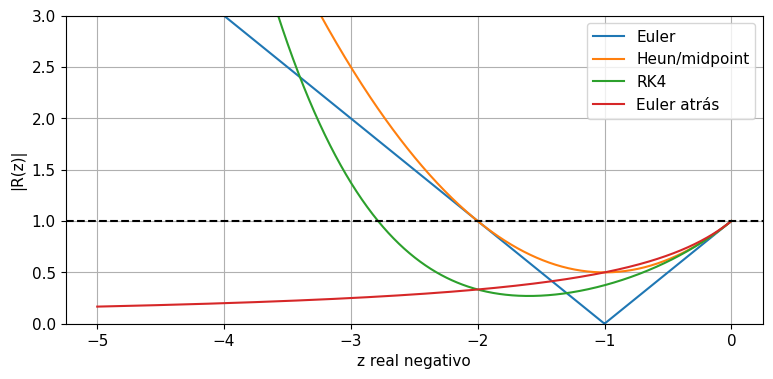

In [2]:
functions={
    "Euler":lambda z:1+z,
    "Heun/midpoint":lambda z:1+z+z*z/2,
    "RK4":lambda z:1+z+z*z/2+z**3/6+z**4/24,
    "Euler atrás":lambda z:1/(1-z)}
z=np.linspace(-5,0,600)
for name,R in functions.items(): plt.plot(z,abs(R(z)),label=name)
plt.axhline(1,color="k",linestyle="--")
plt.ylim(0,3); plt.xlabel("z real negativo"); plt.ylabel("|R(z)|")
plt.legend(); plt.show()

**Interpretación.** Los segmentos bajo la línea uno muestran pasos estables para decaimiento real. La figura recorta valores grandes de métodos explícitos: eso no elimina su crecimiento, solo permite comparar los cruces relevantes.

## 3. Regiones en el plano complejo

Los autovalores complejos aparecen en osciladores y sistemas acoplados. Dibujamos el contorno $|R(z)|=1$. Euler tiene un disco de centro $-1$ y radio uno; Heun y RK4 presentan formas diferentes; Euler atrás incluye todo el semiplano izquierdo.

Al reducir $h$, todos los puntos $h\lambda_j$ se acercan al origen. Elegir paso implica colocar los modos del problema dentro de la región adecuada y además resolver con precisión los observables.

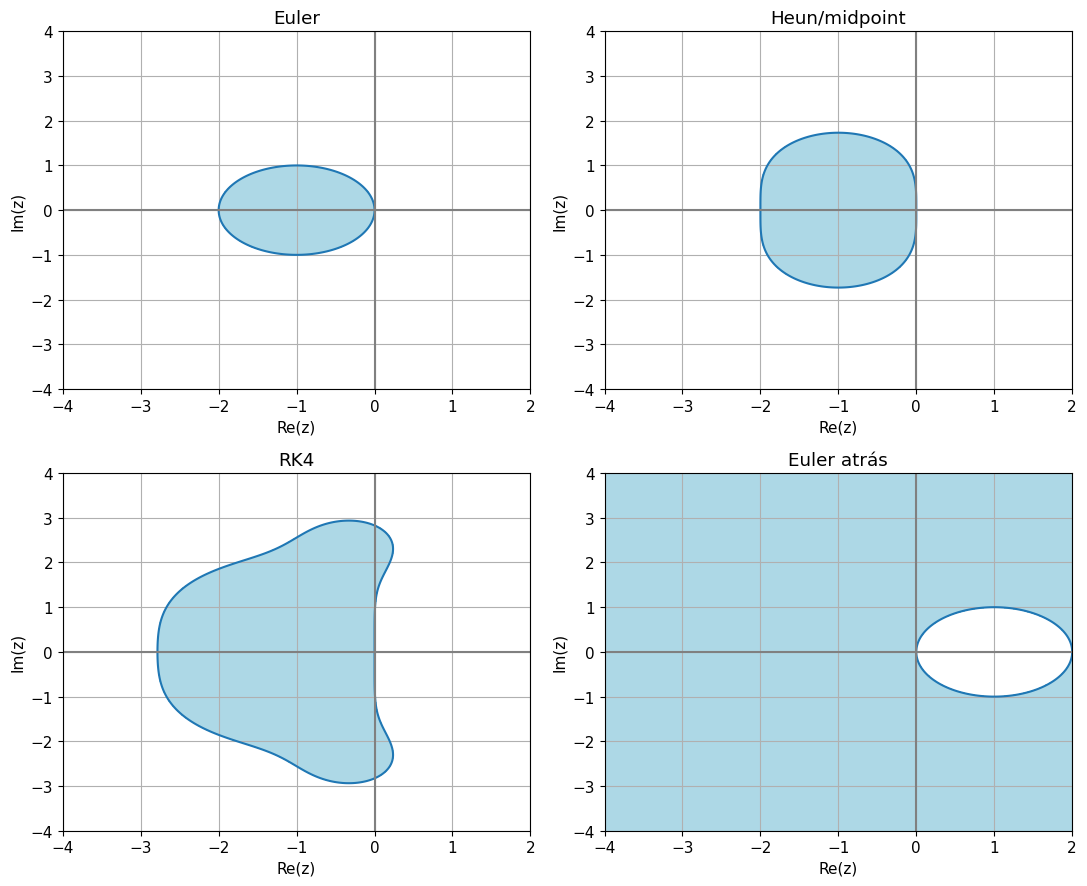

In [3]:
re=np.linspace(-4,2,360); im=np.linspace(-4,4,360)
Z=re[None,:]+1j*im[:,None]
fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,(name,R) in zip(axes.flat,functions.items()):
    with np.errstate(divide="ignore",invalid="ignore"): magnitude=abs(R(Z))
    ax.contourf(re,im,magnitude<=1,levels=[-0.5,0.5,1.5],colors=["white","lightblue"])
    ax.contour(re,im,magnitude,levels=[1],colors="tab:blue")
    ax.axhline(0,color="gray"); ax.axvline(0,color="gray")
    ax.set(title=name,xlabel="Re(z)",ylabel="Im(z)")
plt.tight_layout(); plt.show()

**Interpretación.** El dominio dibujado es finito; Euler atrás sigue estable hacia la izquierda fuera del recuadro. El polo en $z=1$ se encuentra en el semiplano de crecimiento físico y no afecta su A-estabilidad.

## 4. Estabilidad física y estabilidad numérica

Consideremos $y'=-4y$, estable físicamente. Euler con $h=0.6$ usa $R=-1.4$ y produce crecimiento oscilatorio. Euler con $h=0.4$ usa $R=-0.6$ y es estable, pero alterna signos. Con $h=0.1$, $R=0.6$ preserva positividad.

Por tanto, estabilidad absoluta, positividad y precisión son tres criterios distintos. No basta que el resultado sea acotado si representa una cantidad que debe permanecer no negativa.

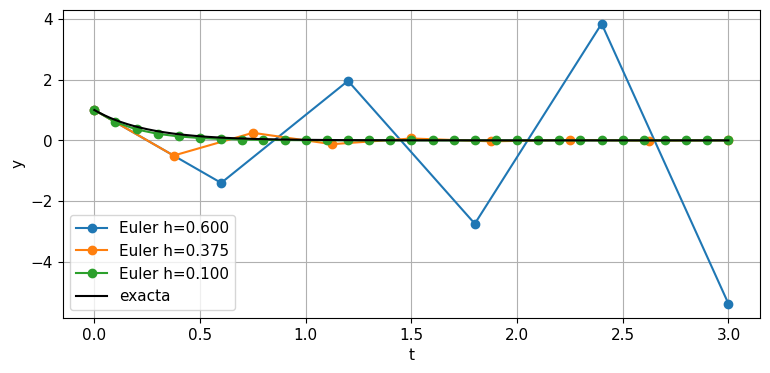

In [4]:
T=3.; k=4.
for n in [5,8,30]:
    t=np.linspace(0,T,n+1); h=T/n
    y=(1-k*h)**np.arange(n+1)
    plt.plot(t,y,"o-",label=f"Euler h={h:.3f}")
q=np.linspace(0,T,500); plt.plot(q,np.exp(-k*q),"k",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** Las diferencias no provienen de un cambio de ecuación: todos los casos usan la misma ley física. La discretización cambia por completo el comportamiento si el paso cruza la región estable.

## 5. Rigidez y varias escalas

Para el sistema diagonal $y_1'=-y_1$, $y_2'=-1000y_2$, el primer modo cambia en escala uno y el segundo en $10^{-3}$. Si solo interesa el modo lento después del transitorio, un explícito aún debe respetar el modo rápido por estabilidad.

Una razón entre magnitudes de autovalores sugiere separación de escalas, pero la rigidez también depende de intervalo, tolerancia y observables. La idea práctica es una restricción de estabilidad mucho más severa que la que pediría precisión en la solución relevante.

RK45 nfev: 2342 nlu: 0 error lento: 6.661338147750939e-16
Radau nfev: 777 nlu: 42 error lento: 1.490057390807209e-07


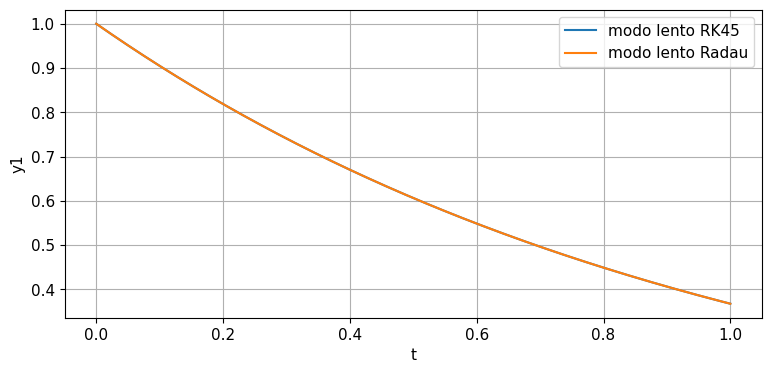

In [5]:
A=np.diag([-1.,-1000.]); T=1.; q=np.linspace(0,T,501)
for method in ["RK45","Radau"]:
    kwargs={} if method=="RK45" else {"jac":A}
    sol=solve_ivp(lambda t,y:A@y,(0,T),[1.,1.],method=method,t_eval=q,
                  rtol=1e-6,atol=1e-9,**kwargs)
    print(method,"nfev:",sol.nfev,"nlu:",sol.nlu,"error lento:",np.max(abs(sol.y[0]-np.exp(-q))))
    plt.plot(q,sol.y[0],label=f"modo lento {method}")
plt.xlabel("t"); plt.ylabel("y1"); plt.legend(); plt.show()

**Interpretación.** Las soluciones lentas pueden ser casi iguales con costes muy diferentes. Una curva correcta no revela cuánto trabajo se invirtió en estabilizar un modo invisible en esa escala de la gráfica.

## 6. A-estabilidad y L-estabilidad

Un método es A-estable si su región contiene todo $\operatorname{Re}z\le0$. Es L-estable si además amortigua completamente modos extremadamente rígidos: $R(z)\to0$ hacia la izquierda. Euler atrás tiene ambas propiedades; trapecio implícito es A-estable pero su límite es $-1$.

Estas propiedades de la ecuación lineal de prueba orientan la elección del solver. Para ODE no lineales, estabilidad no lineal y convergencia del solve interno requieren análisis adicional. En PDE también aparecen condiciones espaciales, fronteras y matrices de gran tamaño.

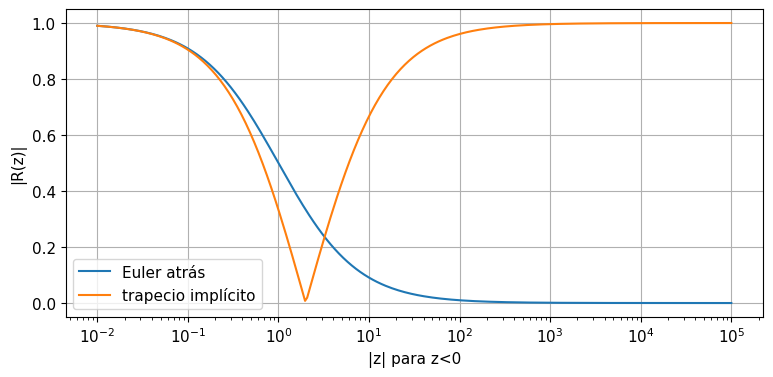

In [6]:
z=-np.logspace(-2,5,300)
plt.semilogx(-z,abs(1/(1-z)),label="Euler atrás")
plt.semilogx(-z,abs((1+z/2)/(1-z/2)),label="trapecio implícito")
plt.xlabel("|z| para z<0"); plt.ylabel("|R(z)|"); plt.legend(); plt.show()

**Interpretación.** Para modos muy rápidos Euler atrás elimina la amplitud por paso, mientras trapecio deja módulo cercano a uno y cambia signo. Esa diferencia importa en problemas dominados por difusión o relajación.

## 7. Matrices no normales y crecimiento transitorio

La matriz
$$A=\begin{pmatrix}-1&M\\0&-2\end{pmatrix}$$
tiene autovalores negativos, pero si $M$ es grande puede amplificar perturbaciones temporalmente. Con $y(0)=(0,1)$,
$$y_2=e^{-2t},\quad y_1=M(e^{-t}-e^{-2t}).$$
La norma crece al principio y después decae. Este crecimiento es físico dentro del sistema lineal, no una inestabilidad numérica. Las regiones basadas solo en autovalores no describen toda la amplificación para matrices no normales.

Autovalores: [-1. -2.] amplificación máxima: 7.504143787051751


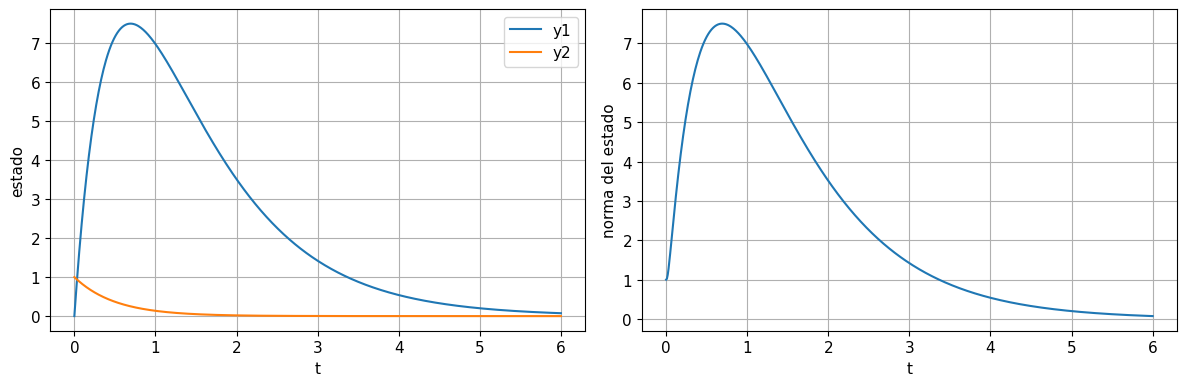

In [7]:
M=30.; A=np.array([[-1.,M],[0.,-2.]])
q=np.linspace(0,6,601)
exact=np.vstack([M*(np.exp(-q)-np.exp(-2*q)),np.exp(-2*q)])
norm=np.linalg.norm(exact,axis=0)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(q,exact[0],label="y1"); ax[0].plot(q,exact[1],label="y2"); ax[0].legend()
ax[0].set(xlabel="t",ylabel="estado")
ax[1].plot(q,norm); ax[1].set(xlabel="t",ylabel="norma del estado")
plt.tight_layout(); plt.show()
print("Autovalores:",np.linalg.eigvals(A),"amplificación máxima:",norm.max())

**Interpretación.** La norma supera ampliamente su valor inicial pese a autovalores estables. Para clasificar el crecimiento como un defecto numérico, compara con la solución exacta o una referencia fiable, no solo con la intuición de decaimiento monótono.

## 8. Consistencia, estabilidad y convergencia

Consistencia significa que la fórmula reproduce la ecuación cuando $h\to0$ con un defecto apropiado. Estabilidad significa controlar la propagación de perturbaciones. Convergencia significa que la solución numérica se acerca a la exacta al refinar.

La identidad de ideas «consistencia + estabilidad ⇒ convergencia» tiene teoremas precisos con hipótesis concretas, como el de equivalencia de Lax para problemas lineales de valor inicial bien planteados y aproximaciones consistentes. No debe citarse como garantía universal para cualquier red, ODE no lineal o implementación arbitraria.

En diferencias finitas para difusión, $\Delta t\le\Delta x^2/(2\alpha)$ en 1D hace visible cómo estabilidad liga discretización temporal y espacial. El capítulo PDE desarrolla esa derivación.

## 9. Protocolo de diagnóstico para simulación y aprendizaje

Identifica modos y escalas, selecciona un método y verifica que $h\lambda$ sea compatible con su región. Después mide precisión al refinar. Comprueba invariantes y cotas físicas por separado. Si la función aprendida introduce modos rápidos durante entrenamiento, un paso que era estable al inicio puede dejar de serlo.

Para una Neural ODE o un modelo corregido por una red, registra también coste del solver a lo largo del ajuste. Un aumento brusco de evaluaciones puede señalar dinámica rígida o irregular creada por el modelo. Una regularización de la función aprendida puede cambiar esas propiedades, pero debe justificarse por el objetivo científico y no solo por hacer al solver más barato.

## 10. Convergencia, error y coste: cómo hacer una comparación justa

El orden depende del método: Euler y Euler atrás tienen $p=1$, Heun y midpoint $p=2$ y RK4 $p=4$. Si un método tiene orden global $p$, en el régimen asintótico se espera $E(h)\approx C h^p$ para problemas suficientemente suaves y un intervalo temporal fijo. El estimador
$$p_{\rm obs}=\log_2\frac{E(h)}{E(h/2)}$$
solo es significativo mientras el error de referencia y el redondeo sean menores que el error medido. Una trayectoria visualmente correcta puede tener error de fase, sesgo en un observable o errores localizados en transitorios.

Para comparar métodos, cuenta evaluaciones de $f$, resoluciones lineales y, en métodos implícitos, iteraciones de Newton. Un método de más orden puede ser más barato para una precisión dada, pero no necesariamente para una tolerancia muy laxa o una función no suave. Si aparecen discontinuidades o eventos, separa los intervalos suaves y localiza el cambio.

Guarda el tiempo final real de cada integración. Usar `int(T/h)` puede terminar antes de $T$ si el cociente no es entero. En estos ejemplos fijamos el número de pasos y calculamos $h=(T-t_0)/N$ para llegar exactamente al extremo. Una malla de salida fija tampoco debe confundirse con los pasos internos de un solver adaptativo.

## 11. De la simulación a SciML

En un problema inverso se ajusta un parámetro $\theta$ minimizando
$$L_h(\theta)=\sum_i\left[y_h(t_i;\theta)-y_i^{\rm obs}\right]^2.$$
El subíndice $h$ recuerda que estamos optimizando la salida de un simulador discretizado. Si el método seleccionado según estabilidad genera un sesgo sistemático, el ajuste puede compensarlo con un parámetro equivocado. Repite la inferencia con una malla más fina y observa si el parámetro estimado cambia.

En una Neural ODE, $f_\theta(t,y)$ puede ser una red, pero el solver conserva sus requisitos de regularidad y estabilidad. Reducir la pérdida de entrenamiento no prueba precisión de integración. Para física diferenciable, una derivada del programa discreto es una sensibilidad de ese programa; hace falta verificar que se estabiliza al refinar la discretización.

Define qué observable importa: valor final, energía, evento, amplitud o una norma de trayectoria. No compares únicamente la apariencia de curvas. Una evaluación científica útil separa error de datos, error de modelo y error numérico, porque mejorar uno de ellos no garantiza mejorar los demás.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_6_Metodos_implicitos.ipynb) | [⏩](../8_PDE/8_1_PDE_fundamentales.ipynb) |